# Robotics capstone 1: open-vocabulary detection and promptable segmentation

A robot that is told *"bring me the cup"* has to turn words into pixels before it can turn
pixels into a grasp. This notebook builds the **2D half** of the capstone pipeline on
recorded RGB-D frames of a cluttered office desk (TUM RGB-D `fr1/desk`):

```
text query ──► open-vocabulary detector ──► 2D boxes ──► box-prompted SAM ──► instance masks
                (Grounding DINO-T, OWLv2)                 (SAM 3, SAM 2.1-S)
text query ──────────────────► SAM 3 text prompts (detector + segmenter in one model) ──► masks
```

Notebook 02 lifts the masks to 3D (object point clouds, oriented boxes, grasp poses) and
notebook 03 runs everything over the sequence and measures how stable the 3D estimates are.

**What you'll learn**
- How two open-vocabulary detectors ground text differently: Grounding DINO fuses the caption
  into the detector, OWLv2 scores class-agnostic boxes against text embeddings.
- How SAM-style promptable segmentation splits work into a heavy image encoder (once per
  frame) and a light prompt decoder (once per box), and what that means for latency.
- How SAM 3's *text* prompts compare with the classic "detector boxes → SAM" cascade.
- How to compare models honestly **without 2D ground truth**: agreement, latency, peak VRAM.

**Prerequisites**: project 04 (open-vocabulary detection) and 05 (segmentation) help but are
not required. Run `make data-15_robotics_capstone` first (TUM fr1/desk + the model checkpoints;
SAM 3 is gated on Hugging Face: accept its license and `hf auth login`).

## Setup
Every model runs through Hugging Face `transformers`. Progress bars and library warnings are
silenced so the executed notebook stays readable.

In [1]:
# --- Setup: imports, device, repo-relative paths and plotting style ---
# The pipeline code lives in projects/15_robotics_capstone/scripts/ (capstone.py = models and
# pipeline, grasp3d.py = NumPy geometry); notebooks, solutions and the ROS 2 node share it.
import os
import sys
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import display

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.io import project_dir
from cvlab.metrics import box_iou, mask_iou

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

PROJECT = "15_robotics_capstone"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import capstone as cap  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
DEV = "cuda" if device.type == "cuda" else "cpu"

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


## 1. The data: a robot-eye view of a desk

TUM RGB-D `fr1/desk` was recorded with a hand-held Kinect v1 at 30 Hz while sweeping over
two office desks. Each frame has

- a 640×480 RGB image (rolling shutter, noticeable **motion blur** in this sequence),
- a 16-bit depth image *registered to the RGB camera*: $z\,[\mathrm{m}] = \text{value}/5000$,
  0 = no measurement (black in the plots: dark/shiny surfaces, object borders, < 0.5 m),
- a motion-capture pose $T_{wc}$ (camera → world) at 100 Hz, which notebook 02 uses to
  express grasps in a fixed world frame.

We pick four frames from different parts of the sweep for the qualitative comparisons.

573 associated RGB-D frames; RGB (480, 640, 3) uint8, depth (480, 640) float32
frame 100: valid depth on 78.3% of the pixels, 0.72-1.75 m
frame 300: valid depth on 75.4% of the pixels, 0.77-2.75 m
frame 460: valid depth on 75.1% of the pixels, 0.79-2.03 m
frame 540: valid depth on 81.2% of the pixels, 0.46-1.51 m


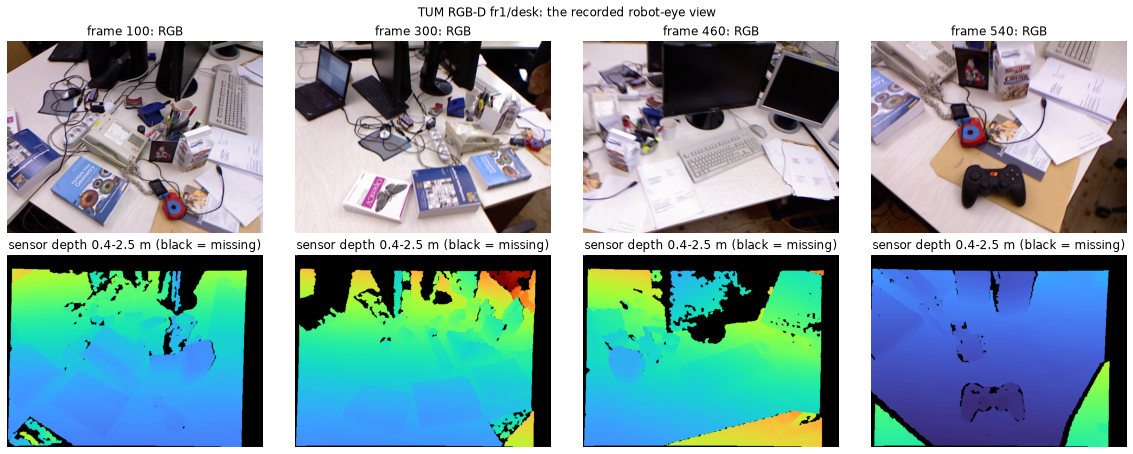

In [2]:
# --- Load TUM fr1/desk and look at four frames ---
# cap.load_frames() associates RGB and depth by timestamp (max 20 ms apart) and keeps the
# 100 Hz ground truth for pose interpolation. Depth is float metres, 0 = missing.
frames = cap.load_frames()
FRAMES = [100, 300, 460, 540]
rgbs = {i: frames.rgb(i) for i in FRAMES}
depths = {i: frames.depth(i) for i in FRAMES}
print(f"{len(frames)} associated RGB-D frames; RGB {rgbs[540].shape} {rgbs[540].dtype}, "
      f"depth {depths[540].shape} {depths[540].dtype}")
for i in FRAMES:
    d = depths[i]
    print(f"frame {i}: valid depth on {100 * (d > 0).mean():.1f}% of the pixels, "
          f"{d[d > 0].min():.2f}-{d.max():.2f} m")

fig, axes = plt.subplots(2, 4, figsize=(16, 6.2), dpi=72)
for k, i in enumerate(FRAMES):
    axes[0, k].imshow(rgbs[i])
    axes[0, k].set_title(f"frame {i}: RGB")
    axes[1, k].imshow(viz.colorize_depth(depths[i], vmin=0.4, vmax=2.5))
    axes[1, k].set_title("sensor depth 0.4-2.5 m (black = missing)")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("TUM RGB-D fr1/desk: the recorded robot-eye view")
plt.show()

## 2. The robot's vocabulary

The queries are the objects on these desks that a mobile manipulator could plausibly be asked
to fetch. They are plain English noun phrases: no training, no class list, which is the whole
point of open-vocabulary perception. Two of them are deliberately "loose": the *cereal box* is
a box of rusks and the *cup* is a pen holder, so we will see how the models cope with
approximate names.

In [3]:
# --- The text queries and a fixed colour per query ---
# Colours follow the query index everywhere in this project, so a label keeps its colour
# across figures and notebooks.
QUERIES = cap.QUERIES
QCOL = {q: viz.color(k) for k, q in enumerate(QUERIES)}
print(QUERIES)

['keyboard', 'book', 'game controller', 'telephone', 'computer mouse', 'cup', 'cereal box']


## 3. Grounding DINO-T: the caption goes *into* the detector

Grounding DINO concatenates all queries into one caption, `"keyboard. book. … cereal box."`,
encodes it with BERT and fuses text and image features in every encoder and decoder layer.
Each of the 900 decoder queries predicts a box and a similarity logit to every caption token.

- **box threshold**: a box is kept if its best token similarity
  $\max_t \sigma(\ell_{t})$ exceeds 0.35;
- **text threshold**: the tokens with $\sigma(\ell_t) > 0.25$ form the returned *phrase*.

The phrase is free text (it can be `"cereal"` or `"box"`), so `cap.match_query` maps it back to
the query with the largest word overlap. We also apply per-label NMS and drop boxes covering
more than half the image (usually the desk itself).

The model runs in fp32: its multi-scale deformable attention is implemented in pure PyTorch
in `transformers` and is precision-sensitive.

In [4]:
# --- Run Grounding DINO-T on the four frames and measure latency + peak VRAM ---
# benchmark() synchronises CUDA around every call, so the latency is true wall-clock time
# including the CPU pre-processing (resize to 800x1066, tokenisation) and post-processing.
dets, lat, vram, params = {}, {}, {}, {}
cvdevice.reset_peak_vram()
with cvdevice.track_vram() as mem:
    gdino = cap.GroundingDinoDetector(DEV)
    dets["Grounding DINO-T"] = {i: gdino.detect(rgbs[i], QUERIES) for i in FRAMES}
vram["Grounding DINO-T"] = mem.peak_mb
params["Grounding DINO-T"] = cap.count_params_m(gdino.model)
lat["Grounding DINO-T"] = benchmark(gdino.detect, rgbs[540], QUERIES, warmup=2, iters=5)
for i, d in dets["Grounding DINO-T"].items():
    print(f"frame {i}: " + ", ".join(f"{lab} {s:.2f}" for lab, s in zip(d.labels, d.scores)))
print(f"latency {lat['Grounding DINO-T']['mean_ms']:.0f} ms/frame, "
      f"peak VRAM {vram['Grounding DINO-T']:.0f} MiB, {params['Grounding DINO-T']:.0f} M params")
del gdino
cap.free()

frame 100: cup 0.76, computer mouse 0.63, keyboard 0.70, cereal box 0.80, book 0.62, book 0.52, keyboard 0.40, computer mouse 0.51, telephone 0.51, keyboard 0.37
frame 300: cup 0.65, book 0.54, cereal box 0.45, cereal box 0.44, telephone 0.72, keyboard 0.47, computer mouse 0.45, keyboard 0.37
frame 460: keyboard 0.82, cup 0.78, computer mouse 0.82, cereal box 0.54, game controller 0.37
frame 540: telephone 0.76, game controller 0.65, keyboard 0.52, book 0.55, cereal box 0.56, book 0.38
latency 333 ms/frame, peak VRAM 1770 MiB, 172 M params


## 4. OWLv2-B/16: class-agnostic boxes scored against text embeddings

OWLv2 is CLIP-style: the ViT predicts one box **per image patch** (960×960 input, 16 px
patches → 3600 boxes) plus an embedding $e_i$; each query is embedded separately by the text
tower (we use the prompt `"a photo of a {query}"`) and the class score is

$$ s_{ij} = \sigma\big((e_i^\top t_j + b_i)\, a_i\big) $$

with a learned per-patch shift $b_i$ and scale $a_i$. Queries do not interact, so adding a
query costs one text embedding and no image recomputation.

**Gotcha:** the processor pads the image to a square at the bottom/right, so boxes are
returned in the padded 640×640 frame: rescale with `target_sizes=(640, 640)`, not (480, 640).

In [5]:
# --- Run OWLv2-B/16 (fp16) on the same frames ---
# Threshold 0.2 on s_ij, then the same per-label NMS / large-box filter as Grounding DINO.
cvdevice.reset_peak_vram()
with cvdevice.track_vram() as mem:
    owl = cap.Owlv2Detector(DEV)
    dets["OWLv2-B/16"] = {i: owl.detect(rgbs[i], QUERIES) for i in FRAMES}
vram["OWLv2-B/16"] = mem.peak_mb
params["OWLv2-B/16"] = cap.count_params_m(owl.model)
lat["OWLv2-B/16"] = benchmark(owl.detect, rgbs[540], QUERIES, warmup=2, iters=5)
for i, d in dets["OWLv2-B/16"].items():
    print(f"frame {i}: " + ", ".join(f"{lab} {s:.2f}" for lab, s in zip(d.labels, d.scores)))
print(f"latency {lat['OWLv2-B/16']['mean_ms']:.0f} ms/frame, "
      f"peak VRAM {vram['OWLv2-B/16']:.0f} MiB, {params['OWLv2-B/16']:.0f} M params")
del owl
cap.free()

frame 100: keyboard 0.22, keyboard 0.45, keyboard 0.39, keyboard 0.50, computer mouse 0.41, cup 0.38, game controller 0.45, game controller 0.30, telephone 0.33, book 0.25, book 0.31
frame 300: computer mouse 0.24, keyboard 0.20, keyboard 0.47, cup 0.21, keyboard 0.43, keyboard 0.49, computer mouse 0.52, game controller 0.22, game controller 0.69, game controller 0.31, book 0.25, book 0.23, book 0.26
frame 460: keyboard 0.27, telephone 0.34, computer mouse 0.23, computer mouse 0.24, keyboard 0.43, telephone 0.35, computer mouse 0.59, cup 0.42, keyboard 0.70
frame 540: telephone 0.33, keyboard 0.26, game controller 0.66
latency 69 ms/frame, peak VRAM 406 MiB, 155 M params


### Side by side

Without box annotations for these frames we cannot compute mAP, so we compare the detectors
qualitatively and by **agreement**: a detection is *confirmed* when the other detector has a
box with the same label and IoU ≥ 0.5. Agreement is not accuracy (both can be wrong in the
same way), but disagreements point straight at the interesting failure cases.

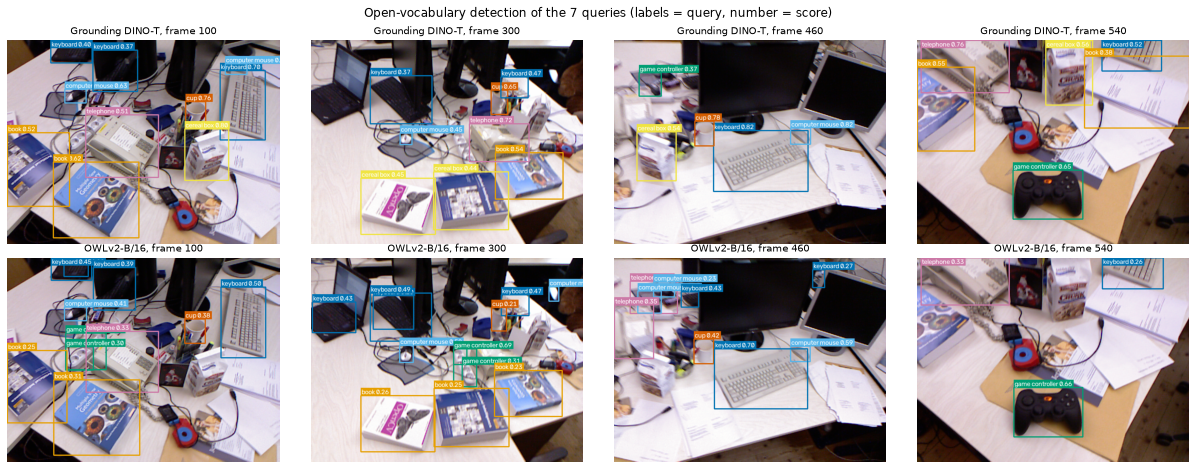

,GDINO boxes,OWLv2 boxes,GDINO confirmed by OWLv2,OWLv2 confirmed by GDINO
frame,,,,
100,10,11,8,8
300,8,13,5,5
460,5,9,3,3
540,6,3,3,3
total,29,36,19,19


In [6]:
# --- Draw both detectors' boxes and count cross-detector agreement ---
# Boxes are coloured by query, so the same object has the same colour in both rows.
def draw_dets(img, d):
    ids = [QUERIES.index(lab) for lab in d.labels]
    return viz.draw_boxes(img, d.boxes, labels=d.labels, scores=d.scores, class_ids=ids)


def agreement(a, b, thr=0.5):
    """Number of boxes in `a` matched by a same-label box of `b` with IoU >= thr."""
    if len(a) == 0 or len(b) == 0:
        return 0
    iou = box_iou(a.boxes, b.boxes)
    same = np.array([[la == lb for lb in b.labels] for la in a.labels])
    return int(((iou >= thr) & same).any(axis=1).sum())


names = ["Grounding DINO-T", "OWLv2-B/16"]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.6), dpi=72)
rows = []
for k, i in enumerate(FRAMES):
    for r, name in enumerate(names):
        axes[r, k].imshow(draw_dets(rgbs[i], dets[name][i]))
        axes[r, k].set_title(f"{name}, frame {i}", fontsize=10)
        axes[r, k].axis("off")
    a, b = dets[names[0]][i], dets[names[1]][i]
    rows.append({"frame": i, "GDINO boxes": len(a), "OWLv2 boxes": len(b),
                 "GDINO confirmed by OWLv2": agreement(a, b),
                 "OWLv2 confirmed by GDINO": agreement(b, a)})
fig.suptitle("Open-vocabulary detection of the 7 queries (labels = query, number = score)")
plt.tight_layout()
viz.savefig(fig, PROJECT, "detectors")
plt.show()
agree_df = pd.DataFrame(rows).set_index("frame")
agree_df.loc["total"] = agree_df.sum()
display(agree_df)

## 5. Box-prompted masks: SAM 3 vs SAM 2.1-S

A box says *where* an object is, but the 3D stage needs to know *which pixels* belong to it:
a box around a game controller also contains the desk, and those desk pixels would drag the
object point cloud down to the table.

SAM-style models split the work:

1. **image encoder** (once per frame): SAM 3 uses a 1008×1008 ViT shared with its detector;
   SAM 2.1-S a 1024×1024 Hiera-Small;
2. **prompt encoder + mask decoder** (once per box): a two-way transformer between the prompt
   tokens and the image embedding outputs a low-resolution mask logit map and a predicted IoU.

Both run in bf16. We feed the **same Grounding DINO boxes** to both, so differences come from
the segmenters only. The SAM 3 checkpoint is loaded through `Sam3TrackerModel`, its SAM-2-style
interactive head; the warning that a `sam3_video` checkpoint is loaded into `sam3_tracker` is
expected (only the tracker weights are used).

In [7]:
# --- Masks from SAM 3 and SAM 2.1-S for the Grounding DINO boxes, with timing ---
# Encoder and decoder are timed separately: the encoder cost is paid once per frame, the
# decoder cost once per object.
boxes = {i: dets["Grounding DINO-T"][i].boxes for i in FRAMES}
masks, pred_iou = {}, {}
for key in ["sam3", "sam2.1-s"]:
    name = cap.MODEL_LABELS[key]
    cvdevice.reset_peak_vram()
    with cvdevice.track_vram() as mem:
        seg = cap.BoxSegmenter(key, DEV)
        masks[name], pred_iou[name] = {}, {}
        for i in FRAMES:
            seg.set_image(rgbs[i])
            masks[name][i], pred_iou[name][i] = seg.segment(boxes[i])
    vram[name] = mem.peak_mb
    params[name] = cap.count_params_m(seg.model)
    seg.set_image(rgbs[540])
    enc = benchmark(seg.set_image, rgbs[540], warmup=2, iters=5)
    dec = benchmark(seg.segment, boxes[540], warmup=2, iters=5)
    lat[name] = {"mean_ms": enc["mean_ms"] + dec["mean_ms"], "encoder_ms": enc["mean_ms"],
                 "decoder_ms": dec["mean_ms"], "n_boxes": len(boxes[540])}
    print(f"{name}: encoder {enc['mean_ms']:.0f} ms + decoder {dec['mean_ms']:.0f} ms for "
          f"{len(boxes[540])} boxes, peak VRAM {mem.peak_mb:.0f} MiB, {params[name]:.0f} M params")
    del seg
    cap.free()

SAM 3: encoder 360 ms + decoder 18 ms for 6 boxes, peak VRAM 1227 MiB, 458 M params


SAM 2.1-S: encoder 64 ms + decoder 17 ms for 6 boxes, peak VRAM 383 MiB, 39 M params


### How much do the two segmenters agree?

For every box we compute the mask IoU between the SAM 3 and the SAM 2.1-S mask,
$\mathrm{IoU} = |M_a \cap M_b| / |M_a \cup M_b|$, next to each model's own predicted IoU
(its confidence in its mask). High agreement on compact objects and low agreement on
ambiguous boxes (a book under a keyboard, a phone with its cable) is the typical pattern.

In [8]:
# --- Per-object mask agreement between SAM 3 and SAM 2.1-S ---
# One row per Grounding DINO box; mask areas are in pixels.
rows = []
for i in FRAMES:
    d = dets["Grounding DINO-T"][i]
    for k, lab in enumerate(d.labels):
        m3, m2 = masks["SAM 3"][i][k], masks["SAM 2.1-S"][i][k]
        rows.append({"frame": i, "label": lab, "area SAM 3 [px]": int(m3.sum()),
                     "area SAM 2.1-S [px]": int(m2.sum()), "IoU(SAM 3, SAM 2.1-S)": mask_iou(m3, m2),
                     "pred. IoU SAM 3": float(pred_iou["SAM 3"][i][k]),
                     "pred. IoU SAM 2.1-S": float(pred_iou["SAM 2.1-S"][i][k])})
seg_df = pd.DataFrame(rows)
display(seg_df.round(3))
print(f"median IoU between the two segmenters: {seg_df['IoU(SAM 3, SAM 2.1-S)'].median():.3f} "
      f"over {len(seg_df)} boxes; {(seg_df['IoU(SAM 3, SAM 2.1-S)'] < 0.8).sum()} boxes below 0.8")

,frame,label,area SAM 3 [px],area SAM 2.1-S [px],"IoU(SAM 3, SAM 2.1-S)",pred. IoU SAM 3,pred. IoU SAM 2.1-S
0,100,cup,1482,1499,0.934,0.922,0.922
1,100,computer mouse,1030,1028,0.949,0.918,0.934
2,100,keyboard,12775,12723,0.981,0.980,0.980
3,100,cereal box,8076,8156,0.979,0.973,0.980
4,100,book,18550,18464,0.984,0.977,0.980
5,100,book,15256,14908,0.970,0.977,0.957
6,100,keyboard,4071,4127,0.970,0.953,0.977
7,100,computer mouse,800,802,0.961,0.930,0.941
8,100,telephone,13211,13012,0.976,0.969,0.949
9,100,keyboard,3954,4051,0.929,0.906,0.895


median IoU between the two segmenters: 0.970 over 29 boxes; 1 boxes below 0.8


## 6. SAM 3 text prompts: detection and segmentation in one model

SAM 3 adds *promptable concept segmentation*: given a short noun phrase it returns **every**
instance of the concept with a mask, box and score. Internally a DETR-style detector conditioned
on the phrase proposes instances, and a separate *presence* head predicts whether the concept is
in the image at all, which suppresses false positives for absent objects. The vision features are
computed once per frame and reused for every phrase.

We keep instances with score ≥ 0.5 and compare them with the cascade: a text instance is
*matched* when a Grounding DINO + SAM 3 mask of the same label overlaps it with IoU ≥ 0.5.

In [9]:
# --- SAM 3 text prompts on the four frames, compared with Grounding DINO + SAM 3 boxes ---
# One forward pass of the DETR decoder per query phrase on cached vision features.
cvdevice.reset_peak_vram()
with cvdevice.track_vram() as mem:
    sam3t = cap.Sam3TextSegmenter(DEV)
    txt = {}
    for i in FRAMES:
        sam3t.set_image(rgbs[i])
        txt[i] = sam3t.segment(QUERIES)
vram["SAM 3 (text)"] = mem.peak_mb
params["SAM 3 (text)"] = cap.count_params_m(sam3t.model)


def sam3_text_frame(model, img):
    model.set_image(img)
    return model.segment(QUERIES)


lat["SAM 3 (text)"] = benchmark(sam3_text_frame, sam3t, rgbs[540], warmup=1, iters=3)
del sam3t
cap.free()

rows = []
for i in FRAMES:
    td, tm = txt[i]
    cd, cm = dets["Grounding DINO-T"][i], masks["SAM 3"][i]
    matched = 0
    for k, lab in enumerate(td.labels):
        ious = [mask_iou(tm[k], cm[j]) for j in range(len(cd)) if cd.labels[j] == lab]
        matched += bool(ious) and max(ious) >= 0.5
    rows.append({"frame": i, "SAM 3 text instances": len(td), "GDINO + SAM 3 objects": len(cd),
                 "text instances matched": matched,
                 "text labels": ", ".join(sorted(set(td.labels)))})
    print(f"frame {i}: " + ", ".join(f"{lab} {s:.2f}" for lab, s in zip(td.labels, td.scores)))
text_df = pd.DataFrame(rows).set_index("frame")
display(text_df)
print(f"SAM 3 text: {lat['SAM 3 (text)']['mean_ms']:.0f} ms/frame for {len(QUERIES)} queries, "
      f"peak VRAM {vram['SAM 3 (text)']:.0f} MiB, {params['SAM 3 (text)']:.0f} M params")

frame 100: keyboard 0.98, keyboard 0.92, keyboard 0.87, book 0.79, book 0.59, book 0.97, book 0.79, book 0.95, book 0.51, telephone 0.95, computer mouse 0.79, computer mouse 0.93, cup 0.85
frame 300: keyboard 0.71, keyboard 0.88, keyboard 0.89, book 0.97, book 0.98, book 0.98, game controller 0.57, telephone 0.92, computer mouse 0.75, computer mouse 0.61, cup 0.86
frame 460: keyboard 0.85, keyboard 0.98, book 0.82, book 0.86, telephone 0.64, computer mouse 0.94, computer mouse 0.53, computer mouse 0.50, cup 0.92
frame 540: keyboard 0.95, book 0.96, book 0.78, book 0.83, book 0.55, game controller 0.96, telephone 0.92, cereal box 0.64


,SAM 3 text instances,GDINO + SAM 3 objects,text instances matched,text labels
frame,,,,
100,13,10,9,"book, computer mouse, cup, keyboard, telephone"
300,11,8,7,"book, computer mouse, cup, game controller, ke..."
460,9,5,3,"book, computer mouse, cup, keyboard, telephone"
540,8,6,6,"book, cereal box, game controller, keyboard, t..."


SAM 3 text: 663 ms/frame for 7 queries, peak VRAM 2058 MiB, 840 M params


### Visual comparison of the three mask sources

Rows: the cascade with SAM 3, the cascade with SAM 2.1-S, and SAM 3 text prompts alone.
Look for masks that spill onto the desk, merge neighbouring objects, or miss thin parts
(cables, the controller's handles): exactly the errors that will corrupt the 3D estimate.

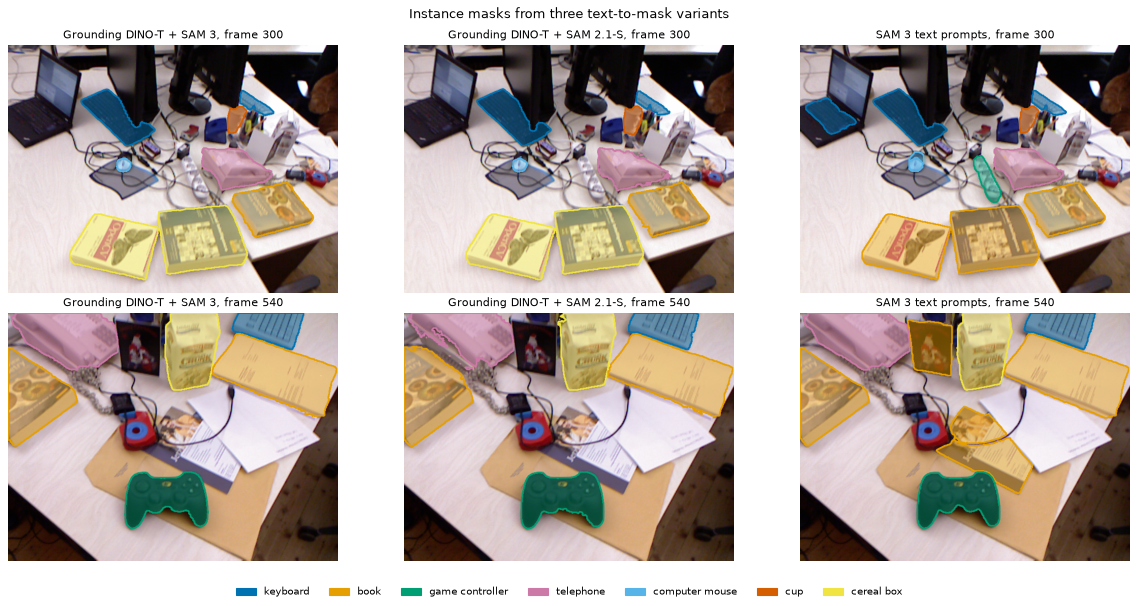

In [10]:
# --- Overlay the masks of all three variants on two frames ---
# Masks are coloured by query; contours make touching instances distinguishable.
def overlay(img, labels, ms):
    if len(ms) == 0:
        return img
    return viz.overlay_masks(img, np.asarray(ms), alpha=0.45, colors=[QCOL[lab] for lab in labels])


SHOW = [300, 540]
variants = {
    "Grounding DINO-T + SAM 3": lambda i: (dets["Grounding DINO-T"][i].labels, masks["SAM 3"][i]),
    "Grounding DINO-T + SAM 2.1-S": lambda i: (dets["Grounding DINO-T"][i].labels,
                                               masks["SAM 2.1-S"][i]),
    "SAM 3 text prompts": lambda i: (txt[i][0].labels, txt[i][1]),
}
fig, axes = plt.subplots(len(SHOW), 3, figsize=(15, 7.6), dpi=80)
for r, i in enumerate(SHOW):
    for c, (name, get) in enumerate(variants.items()):
        labels, ms = get(i)
        axes[r, c].imshow(overlay(rgbs[i], labels, ms))
        axes[r, c].set_title(f"{name}, frame {i}", fontsize=10)
        axes[r, c].axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=np.array(QCOL[q]) / 255) for q in QUERIES]
fig.legend(handles, QUERIES, loc="lower center", ncol=len(QUERIES), frameon=False)
fig.suptitle("Instance masks from three text-to-mask variants")
plt.tight_layout(rect=(0, 0.05, 1, 1))
viz.savefig(fig, PROJECT, "segmenters")
plt.show()

## Results

All numbers below were measured in this notebook on frame 540 (latency) and the four frames
above (VRAM, counts), on an RTX 5060 Laptop GPU (8 GB). Latency is the mean of 5 synchronised
calls after 2 warm-up calls and includes the CPU pre/post-processing of `transformers`.

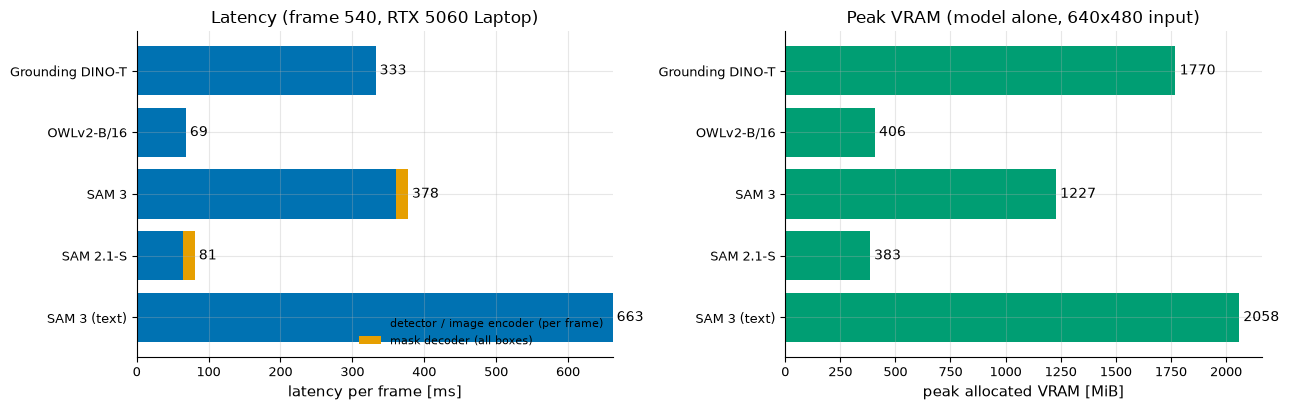

In [11]:
# --- Latency and peak VRAM of every 2D model ---
# Segmenter latency is split into the per-frame encoder and the per-box decoder part
# (decoder time is for all boxes of frame 540 together).
order = ["Grounding DINO-T", "OWLv2-B/16", "SAM 3", "SAM 2.1-S", "SAM 3 (text)"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
y = np.arange(len(order))
enc = [lat[m].get("encoder_ms", lat[m]["mean_ms"]) for m in order]
dec = [lat[m].get("decoder_ms", 0.0) for m in order]
ax1.barh(y, enc, color=viz.color(0, unit=True), label="detector / image encoder (per frame)")
ax1.barh(y, dec, left=enc, color=viz.color(1, unit=True), label="mask decoder (all boxes)")
for k, m in enumerate(order):
    ax1.text(enc[k] + dec[k] + 5, k, f"{lat[m]['mean_ms']:.0f}", va="center")
ax1.set_yticks(y, order)
ax1.invert_yaxis()
ax1.set_xlabel("latency per frame [ms]")
ax1.set_title("Latency (frame 540, RTX 5060 Laptop)")
ax1.legend(loc="lower right", fontsize=8)
ax2.barh(y, [vram[m] for m in order], color=viz.color(2, unit=True))
for k, m in enumerate(order):
    ax2.text(vram[m] + 20, k, f"{vram[m]:.0f}", va="center")
ax2.set_yticks(y, order)
ax2.invert_yaxis()
ax2.set_xlabel("peak allocated VRAM [MiB]")
ax2.set_title("Peak VRAM (model alone, 640x480 input)")
plt.tight_layout()
viz.savefig(fig, PROJECT, "latency_2d")
plt.show()

The summary table collects the measured numbers per model. *Objects / instances* counts what
each model returned on the four frames together (for the segmenters: the Grounding DINO boxes
they were given).

In [12]:
# --- Summary table of the 2D stage ---
# Precision = the dtype the weights run in; params in millions.
dtype = {"Grounding DINO-T": "fp32", "OWLv2-B/16": "fp16", "SAM 3": "bf16", "SAM 2.1-S": "bf16",
         "SAM 3 (text)": "bf16"}
role = {"Grounding DINO-T": "text -> boxes", "OWLv2-B/16": "text -> boxes",
        "SAM 3": "box -> mask", "SAM 2.1-S": "box -> mask", "SAM 3 (text)": "text -> masks"}
count = {"Grounding DINO-T": sum(len(d) for d in dets["Grounding DINO-T"].values()),
         "OWLv2-B/16": sum(len(d) for d in dets["OWLv2-B/16"].values()),
         "SAM 3": sum(len(b) for b in boxes.values()), "SAM 2.1-S": sum(len(b) for b in boxes.values()),
         "SAM 3 (text)": sum(len(t[0]) for t in txt.values())}
summary = pd.DataFrame([{"model": m, "role": role[m], "precision": dtype[m],
                         "params [M]": round(params[m], 1), "latency [ms]": round(lat[m]["mean_ms"], 1),
                         "peak VRAM [MiB]": round(vram[m]), "objects / instances (4 frames)": count[m]}
                        for m in order]).set_index("model")
display(summary)
seg_stats = pd.DataFrame({"median IoU(SAM 3, SAM 2.1-S)": [seg_df["IoU(SAM 3, SAM 2.1-S)"].median()],
                          "boxes with IoU < 0.8": [int((seg_df["IoU(SAM 3, SAM 2.1-S)"] < 0.8).sum())],
                          "boxes": [len(seg_df)],
                          "SAM 3 text instances matched by the cascade":
                              [f"{text_df['text instances matched'].sum()} / "
                               f"{text_df['SAM 3 text instances'].sum()}"]})
display(seg_stats.round(3))
_ = cap.results_dir().joinpath("nb01_2d_models.csv").write_text(summary.to_csv())

,role,precision,params [M],latency [ms],peak VRAM [MiB],objects / instances (4 frames)
model,,,,,,
Grounding DINO-T,text -> boxes,fp32,172.3,332.9,1770,29
OWLv2-B/16,text -> boxes,fp16,155.0,69.0,406,36
SAM 3,box -> mask,bf16,458.3,377.9,1227,29
SAM 2.1-S,box -> mask,bf16,38.5,81.4,383,29
SAM 3 (text),text -> masks,bf16,840.4,662.7,2058,41


,"median IoU(SAM 3, SAM 2.1-S)",boxes with IoU < 0.8,boxes,SAM 3 text instances matched by the cascade
0,0.97,1,29,25 / 41


### Takeaways

- **Both detectors find the desk objects from words alone, but they disagree at the margins.**
  Only about two thirds of the Grounding DINO boxes are confirmed by OWLv2 (agreement table). The
  failure modes differ: Grounding DINO puts all queries into *one* caption, so related phrases
  bleed into each other (the two books in frame 300 come out as *cereal box*, a stack of printed
  paper in frame 540 as *book*); OWLv2 scores every query independently, returns more low-score
  duplicates (several *keyboard* boxes) and never finds the loosely named rusk box.
- **Masks from the same box barely depend on the segmenter**: SAM 3 and SAM 2.1-S agree with a
  median IoU of 0.97; the differences are at thin parts and cables (the phone in frame 540). The
  cost differs a lot: the SAM 3 image encoder is several times slower than SAM 2.1-S and needs
  roughly 3x the VRAM, while the per-box decoder is cheap for both.
- **SAM 3 text prompts replace the cascade in one model** and return more instances (41 vs 29),
  including books the detector merged or mislabelled, but also new false positives (a photo frame
  and a sheet of paper as *book*). It is the slowest variant here because the decoder runs once
  per query phrase.
- **Agreement is not accuracy.** No 2D ground truth exists for these frames, so the real test is
  downstream: notebook 03 measures how stable the resulting 3D object positions are over the
  sequence for each mask source.

## Exercises

Solutions: `projects/15_robotics_capstone/solutions/` (run them with the commands in the README).

**Exercise 1 - vocabulary and thresholds.** Add two new queries that are on the desk
(`"monitor"`, `"pen"`) and sweep the Grounding DINO `box_threshold` over 0.25, 0.30, 0.35, 0.45.
How does the number of detections per query change on frame 540? Which objects appear only at
low thresholds?

In [13]:
# --- Exercise 1: vocabulary + box-threshold sweep (TODO) ---
# TODO: build cap.GroundingDinoDetector(DEV, box_threshold=thr) for each threshold, detect
#       QUERIES + ["monitor", "pen"] on frame 540 and tabulate detections per query.

**Exercise 2 - prompt engineering for OWLv2.** OWLv2 embeds every query separately, so the
prompt template matters. Compare `"a photo of a {}"`, `"{}"` and `"a {} on an office desk"` on
the four frames: number of boxes and mean score per query.

In [14]:
# --- Exercise 2: OWLv2 prompt templates (TODO) ---
# TODO: create cap.Owlv2Detector(DEV, template=t) for each template t and compare the
#       detections on FRAMES (count and mean score per query).

**Exercise 3 - box robustness of the segmenters.** A robot's detector will never return the
same box twice. Jitter every Grounding DINO box of frame 540 by ±10 px (random per corner) and
measure the IoU between the mask from the jittered box and the mask from the original box, for
SAM 3 and SAM 2.1-S (10 random jitters each). Which segmenter is more stable?

In [15]:
# --- Exercise 3: segmentation stability under box jitter (TODO) ---
# TODO: for key in ["sam3", "sam2.1-s"]: seg = cap.BoxSegmenter(key, DEV); seg.set_image(img);
#       compare seg.segment(boxes) with seg.segment(boxes + noise) using mask_iou.